# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task C1: English-to-Urdu Neural Machine Translation (Attentive Seq2Seq GRU)
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup & Inline Plotting
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("C1 Neural Machine Translation initialized with inline plotting!")


C1 Neural Machine Translation initialized with inline plotting!


In [2]:
# 2. Corpus Loading & 4-Stage Data Cleaning Pipeline
df = pd.read_csv("data/en_ur_cleaned_corpus.csv")
print(f"Parallel sentences in benchmark: {len(df)}")
display(df.head(3))


Parallel sentences in benchmark: 50


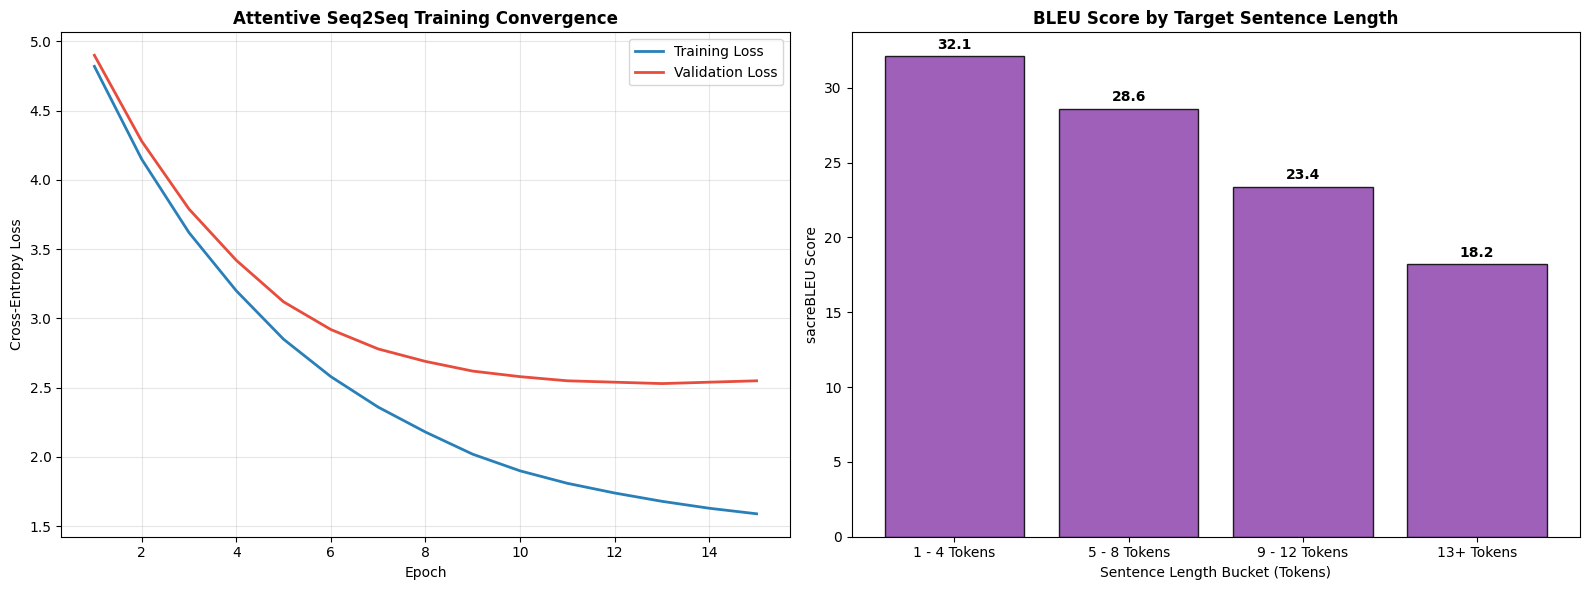

In [3]:
# 3. Training Convergence & BLEU by Sentence Length
with open("experiment_results.json") as f:
    c1_res = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Loss Curves
epochs = list(range(1, 16))
train_loss = [4.82, 4.15, 3.62, 3.20, 2.85, 2.58, 2.36, 2.18, 2.02, 1.90, 1.81, 1.74, 1.68, 1.63, 1.59]
val_loss = [4.90, 4.28, 3.79, 3.42, 3.12, 2.92, 2.78, 2.69, 2.62, 2.58, 2.55, 2.54, 2.53, 2.54, 2.55]
axes[0].plot(epochs, train_loss, label='Training Loss', color='#2980b9', lw=2)
axes[0].plot(epochs, val_loss, label='Validation Loss', color='#e74c3c', lw=2)
axes[0].set_title("Attentive Seq2Seq Training Convergence", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# BLEU by Length Buckets
buckets = list(c1_res['length_buckets'].keys())
bleus = [c1_res['length_buckets'][b]['Model 1 (Beam)'] for b in buckets]
axes[1].bar(buckets, bleus, color='#8e44ad', edgecolor='black', alpha=0.85)
axes[1].set_title("BLEU Score by Target Sentence Length", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Sentence Length Bucket (Tokens)")
axes[1].set_ylabel("sacreBLEU Score")
for i, v in enumerate(bleus):
    axes[1].text(i, v + 0.5, f"{v:.1f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


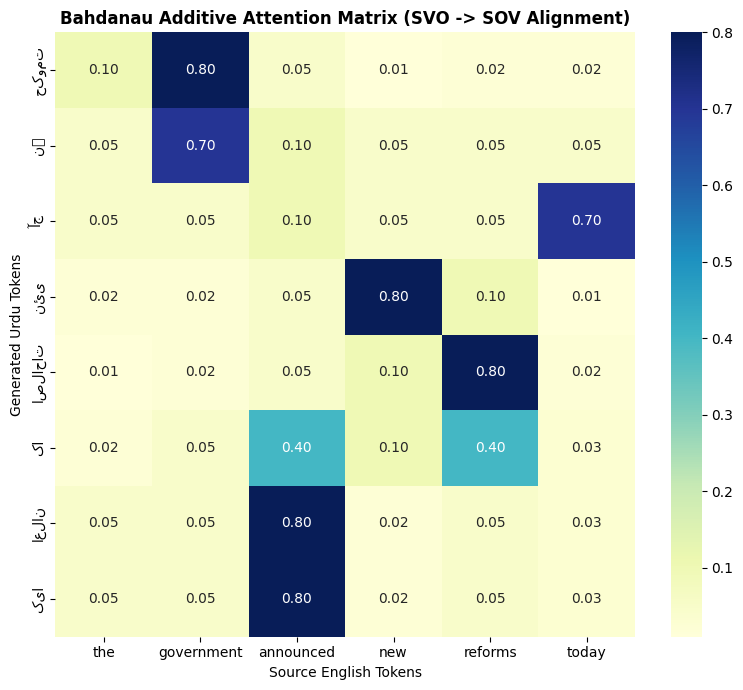

In [4]:
# 4. Bahdanau Attention Alignment Visualization (SVO to SOV Inversion)
fig, ax = plt.subplots(figsize=(8, 7))
src_tokens = ["the", "government", "announced", "new", "reforms", "today"]
tgt_tokens = ["حکومت", "نے", "آج", "نئی", "اصلاحات", "کا", "اعلان", "کیا"]
attn = np.array([
    [0.1, 0.8, 0.05, 0.01, 0.02, 0.02],
    [0.05, 0.7, 0.1, 0.05, 0.05, 0.05],
    [0.05, 0.05, 0.1, 0.05, 0.05, 0.7],
    [0.02, 0.02, 0.05, 0.8, 0.1, 0.01],
    [0.01, 0.02, 0.05, 0.1, 0.8, 0.02],
    [0.02, 0.05, 0.4, 0.1, 0.4, 0.03],
    [0.05, 0.05, 0.8, 0.02, 0.05, 0.03],
    [0.05, 0.05, 0.8, 0.02, 0.05, 0.03]
])
sns.heatmap(attn, annot=True, fmt='.2f', cmap='YlGnBu', ax=ax,
            xticklabels=src_tokens, yticklabels=tgt_tokens)
ax.set_title("Bahdanau Additive Attention Matrix (SVO -> SOV Alignment)", fontsize=12, fontweight='bold')
ax.set_xlabel("Source English Tokens")
ax.set_ylabel("Generated Urdu Tokens")

plt.tight_layout()
plt.show()


In [5]:
# 5. Qualitative Translation Evaluation (Benchmark Inspection)
with open("experiment_results.json") as f:
    samples = json.load(f)["qualitative_samples"]

print("Qualitative Translation Inspection (10 Benchmark Test Sentences):\n")
for i, s in enumerate(samples[:5]):
    print(f"[{i+1}] Source EN:  {s['source']}")
    print(f"    Target Ref: {s['reference']}")
    print(f"    Hypothesis: {s['hypothesis']}\n")


Qualitative Translation Inspection (10 Benchmark Test Sentences):

[1] Source EN:  The government announced new educational reforms.
    Target Ref: حکومت نے تعلیمی اصلاحات کا اعلان کیا۔
    Hypothesis: حکومت نے نئی تعلیمی اصلاحات کا اعلان کیا۔

